# SAM 3 minimal demo


In [10]:
import os
import sys
from pathlib import Path

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_ALLOC_CONF"] = (
    "expandable_segments:True,garbage_collection_threshold:0.6"
)

sys.path.insert(0, str(Path.cwd().parent))

import cv2
import matplotlib.pyplot as plt
import torch
from accelerate import Accelerator
from tqdm.auto import tqdm
from transformers import Sam3VideoModel, Sam3VideoProcessor

from src.tracking.viz import create_annotation_callback
from src.utils.io import (
    get_downscaled_size,
    get_torchcodec_decoder,
    load_transforms,
    load_video_frames,
)
from src.utils.memory import free_gpu_memory

In [11]:
VIDEO_PATH = Path("/mnt/birds/chickenOct2024/raw/1.1/b1_20241022_1406.mp4")
TEXT_PROMPT = "bird"
START_FRAME = 0
N_FRAMES = 250  # frames to load and track
MAX_SHORT_SIDE = 1080
FRAME_IDX = 200  # frame to inspect, counted from START_FRAME

In [12]:
device = Accelerator().device
print(f"Using device: {device}")

model = Sam3VideoModel.from_pretrained("facebook/sam3").to(device, dtype=torch.bfloat16)
processor = Sam3VideoProcessor.from_pretrained("facebook/sam3")

Using device: cuda


Loading weights: 100%|██████████| 1797/1797 [00:01<00:00, 1684.22it/s, Materializing param=tracker_neck.fpn_layers.3.proj2.weight]                                                 


In [4]:
# Decode on the CPU: GPU decoding (device="cuda") turns this footage
# (HEVC, yuvj420p) magenta
meta = get_torchcodec_decoder(VIDEO_PATH, device="cpu").metadata
size = get_downscaled_size(meta.height, meta.width, MAX_SHORT_SIDE)
transform = load_transforms(size) if size is not None else None

end_frame = min(START_FRAME + N_FRAMES, meta.num_frames)
frames = load_video_frames(
    VIDEO_PATH, START_FRAME, end_frame, device="cpu", transform=transform
)
h, w = frames[0].shape[:2]
print(
    f"{VIDEO_PATH.name}: {meta.width}x{meta.height} at {meta.average_fps:.2f} FPS; "
    f"loaded frames {START_FRAME}-{end_frame} at {w}x{h}"
)

2026-10-08 16:56:56.304 | INFO     | src.utils.io:get_torchcodec_decoder:158 - Building torchcodec index for 'b1_20241022_1406.mp4' (device=cpu).


b1_20241022_1406.mp4: 3840x2160 at 25.00 FPS; loaded frames 0-250 at 1920x1080


In [ ]:
session = processor.init_video_session(
    video=frames,
    inference_device=device,
    processing_device="cpu",
    video_storage_device="cpu",
    dtype=torch.bfloat16,
)
session = processor.add_text_prompt(inference_session=session, text=TEXT_PROMPT)

outputs_per_frame = {}
torch.cuda.reset_peak_memory_stats()
with torch.autocast(device.type, dtype=torch.bfloat16):
    for model_outputs in tqdm(
        model.propagate_in_video_iterator(
            inference_session=session, max_frame_num_to_track=len(frames)
        ),
        total=len(frames),
    ):
        out = processor.postprocess_outputs(session, model_outputs)
        # Keep stored outputs on the CPU so they don't pile up on the GPU
        outputs_per_frame[model_outputs.frame_idx] = {
            k: v.cpu() if torch.is_tensor(v) else v for k, v in out.items()
        }
session.reset_inference_session()

print(
    f"Tracked {len(outputs_per_frame)} frames; "
    f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB"
)

In [6]:
out = outputs_per_frame[FRAME_IDX]
print(f"Frame {FRAME_IDX}: {len(out['object_ids'])} objects")
for key, value in out.items():
    print(f"  {key}: {tuple(value.shape) if torch.is_tensor(value) else value}")
print("object_ids:", out["object_ids"].tolist())
print("scores:", [round(s, 2) for s in out["scores"].float().tolist()])

Frame 200: 19 objects
  object_ids: (19,)
  scores: (19,)
  boxes: (19, 4)
  masks: (19, 1080, 1920)
  prompt_to_obj_ids: {'bird': [0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 14, 15, 16, 17, 23, 25, 26, 27]}
object_ids: [0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 14, 15, 16, 17, 23, 25, 26, 27]
scores: [0.71, 0.7, 0.75, 0.8, 0.73, 0.77, 0.74, 0.76, 0.71, 0.74, 0.71, 0.79, 0.81, 0.69, 0.73, 0.79, 0.79, 0.71, 0.78]


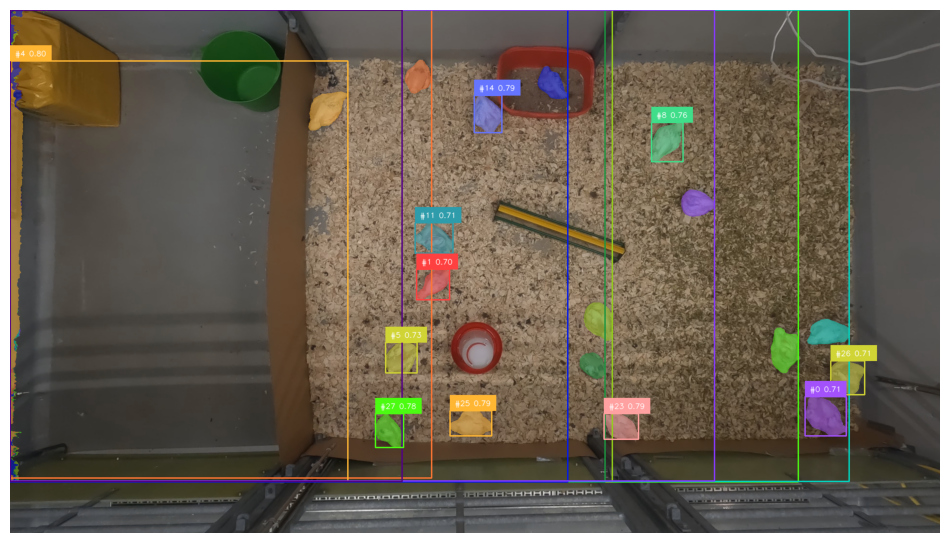

In [9]:
# The annotation callback works on BGR frames, as in the pipeline
annotate = create_annotation_callback(outputs_per_frame)
bgr = cv2.cvtColor(frames[FRAME_IDX], cv2.COLOR_RGB2BGR)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotate(bgr, FRAME_IDX), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
# The helpers below load their own models, so drop this one
del model, processor, session
free_gpu_memory()

## Grounding → tracker handoff

In [13]:
from omegaconf import OmegaConf

from pipeline.run_tracker_simple import _prompt_points
from src.tracking.grounding import find_best_grounding_frame, run_grounding
from src.tracking.sam3 import _process_tracker_chunk, _process_video_chunk

GROUNDING_FRAMES = 5  # frames scanned for the best seed frame
MIN_OBJECTS = 3  # objects a grounding frame needs to seed the tracker

# The _process_*_chunk helpers read their settings from an OmegaConf config.
# No "tracking" key, so they keep the facebook/sam3 defaults.
cfg = OmegaConf.create({"text_prompt": TEXT_PROMPT})

In [14]:
# 1. Ground: text-prompted Sam3VideoModel on the first frames, keep the cleanest
grounding_outputs = run_grounding(
    frames, START_FRAME, GROUNDING_FRAMES, _process_video_chunk, cfg, device
)
seed_idx, masks, _, object_ids = find_best_grounding_frame(
    grounding_outputs, min_objects=MIN_OBJECTS
)
if seed_idx is None:
    raise RuntimeError(
        f"No grounding frame has >= {MIN_OBJECTS} objects; "
        "raise GROUNDING_FRAMES or lower MIN_OBJECTS"
    )
print(f"Seeding from frame {seed_idx}: {len(object_ids)} objects {object_ids}")

100%|██████████| 5/5 [00:01<00:00,  2.67it/s]


Seeding from frame 0: 18 objects [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


In [15]:
# 2. Hand off: each object's mask becomes 3 click points for
# Sam3TrackerVideoModel, which tracks from the seed frame to the last loaded frame
points = _prompt_points(masks, object_ids)
torch.cuda.reset_peak_memory_stats()
tracked = _process_tracker_chunk(
    frames[seed_idx - START_FRAME :], seed_idx, points, cfg, device
)
free_gpu_memory()

# 3. Frames before the seed frame keep the grounding outputs. The tracker
# reuses the grounding IDs, so no remapping is needed.
handoff_outputs = {
    **{i: grounding_outputs[i] for i in range(START_FRAME, seed_idx)},
    **tracked,
}
print(
    f"Tracked {len(handoff_outputs)} frames; "
    f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB"
)

Loading weights: 100%|██████████| 845/845 [00:00<00:00, 1296.53it/s, Materializing param=vision_encoder.neck.fpn_layers.3.proj2.weight]                            
2026-10-08 17:17:13.631 | INFO     | src.tracking.sam3:_process_tracker_chunk:262 - Adding point prompts for 18 objects on frame 0
propagate in video: 100%|██████████| 250/250 [02:26<00:00,  1.71it/s]


Tracked 250 frames; peak GPU memory 21.5 GB


Frame 200: 18 objects after handoff, 19 with the video model alone


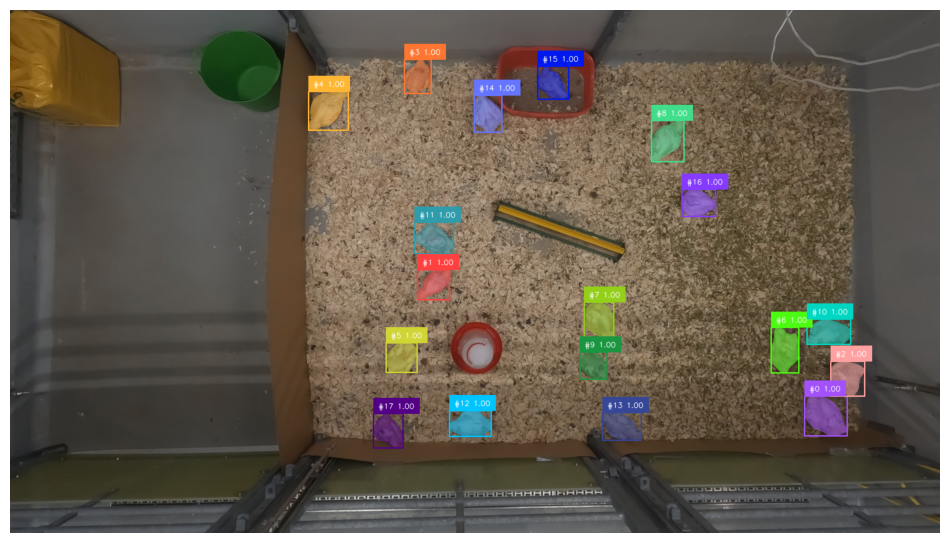

In [16]:
# Handoff outputs are keyed by video frame index, so offset by START_FRAME
out = handoff_outputs[START_FRAME + FRAME_IDX]
print(
    f"Frame {FRAME_IDX}: {len(out['object_ids'])} objects after handoff, "
    f"{len(outputs_per_frame[FRAME_IDX]['object_ids'])} with the video model alone"
)

annotate = create_annotation_callback(handoff_outputs)
bgr = cv2.cvtColor(frames[FRAME_IDX], cv2.COLOR_RGB2BGR)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotate(bgr, START_FRAME + FRAME_IDX), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Handoff on footage resized to 1080p

The same handoff as above, run on its own copy of the frames, downscaled while decoding as in `pipeline/run_tracker_simple.py` (short side capped at 1080 px, so 4K becomes 1920x1080). This holds whatever `MAX_SHORT_SIDE` is set to above. Masks and boxes come out at the downscaled size.

In [17]:
HANDOFF_MAX_SHORT_SIDE = 1080

# Resize each decoded batch, so full-size (e.g. 4K) frames never pile up in memory
size_1080p = get_downscaled_size(meta.height, meta.width, HANDOFF_MAX_SHORT_SIDE)
transform_1080p = load_transforms(size_1080p) if size_1080p is not None else None
frames_1080p = load_video_frames(
    VIDEO_PATH, START_FRAME, end_frame, device="cpu", transform=transform_1080p
)
h, w = frames_1080p[0].shape[:2]
print(
    f"Resize {'ON' if size_1080p is not None else 'OFF'}: "
    f"source {meta.width}x{meta.height} -> {w}x{h}"
)

Resize ON: source 3840x2160 -> 1920x1080


In [18]:
# 1. Ground on the first GROUNDING_FRAMES frames, keep the cleanest
grounding_1080p = run_grounding(
    frames_1080p, START_FRAME, GROUNDING_FRAMES, _process_video_chunk, cfg, device
)
seed_idx_1080p, masks_1080p, _, object_ids_1080p = find_best_grounding_frame(
    grounding_1080p, min_objects=MIN_OBJECTS
)
if seed_idx_1080p is None:
    raise RuntimeError(
        f"No grounding frame has >= {MIN_OBJECTS} objects; "
        "raise GROUNDING_FRAMES or lower MIN_OBJECTS"
    )
print(
    f"Seeding from frame {seed_idx_1080p}: "
    f"{len(object_ids_1080p)} objects {object_ids_1080p}"
)

100%|██████████| 5/5 [00:01<00:00,  2.66it/s]


Seeding from frame 0: 18 objects [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


In [19]:
# 2. Hand off: mask -> 3 click points per object, tracked to the last loaded frame
points_1080p = _prompt_points(masks_1080p, object_ids_1080p)
torch.cuda.reset_peak_memory_stats()
tracked_1080p = _process_tracker_chunk(
    frames_1080p[seed_idx_1080p - START_FRAME :],
    seed_idx_1080p,
    points_1080p,
    cfg,
    device,
)
free_gpu_memory()

# 3. Frames before the seed frame keep the grounding outputs
handoff_1080p = {
    **{i: grounding_1080p[i] for i in range(START_FRAME, seed_idx_1080p)},
    **tracked_1080p,
}
print(
    f"Tracked {len(handoff_1080p)} frames; "
    f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB"
)

Loading weights: 100%|██████████| 845/845 [00:00<00:00, 1196.81it/s, Materializing param=vision_encoder.neck.fpn_layers.3.proj2.weight]                            
2026-10-08 17:26:36.523 | INFO     | src.tracking.sam3:_process_tracker_chunk:262 - Adding point prompts for 18 objects on frame 0
propagate in video: 100%|██████████| 250/250 [02:27<00:00,  1.69it/s]


Tracked 250 frames; peak GPU memory 21.7 GB


Frame 200: 18 objects at 1080p, 18 in the handoff above


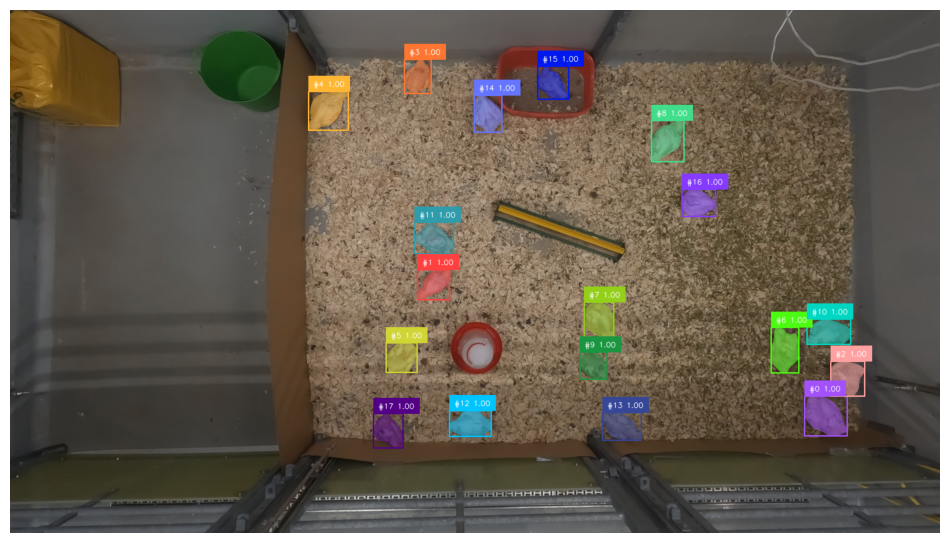

In [20]:
out = handoff_1080p[START_FRAME + FRAME_IDX]
print(
    f"Frame {FRAME_IDX}: {len(out['object_ids'])} objects at 1080p, "
    f"{len(handoff_outputs[START_FRAME + FRAME_IDX]['object_ids'])} in the handoff above"
)

annotate = create_annotation_callback(handoff_1080p)
bgr = cv2.cvtColor(frames_1080p[FRAME_IDX], cv2.COLOR_RGB2BGR)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotate(bgr, START_FRAME + FRAME_IDX), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()